# 09.2 · Sentiment classifier on product reviews

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/09-nlp-genai/02-sentiment-classifier/lesson.ipynb)

Read the [README](README.md) first. This notebook checks the toy votes, trains three versions of the classifier, opens up its coefficients and reads its mistakes.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import os, logging, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, str(data_path("download.py").parent))

## 1. The toy model from the README

In [2]:
votes = {"great": 2, "good": 1, "not": -2, "bad": -2}

def toy_score(review):
    words = review.lower().replace(",", "").split()
    z = sum(votes.get(w, 0) for w in words)
    return z, 1 / (1 + np.exp(-z))

for review in ["great mug, great price", "great mug but not great", "not good", "not bad"]:
    z, p = toy_score(review)
    print(f"{review:26}  z = {z:+d}   P(positive) = {p:.3f}")

great mug, great price      z = +4   P(positive) = 0.982
great mug but not great     z = +2   P(positive) = 0.881
not good                    z = -1   P(positive) = 0.269
not bad                     z = -4   P(positive) = 0.018


## 2. The reviews

In [3]:
from download import load_reviews
from sklearn.model_selection import train_test_split

reviews = load_reviews()          # first run downloads one 117 MB file, then cached
train, test = train_test_split(reviews, test_size=0.2, random_state=42, stratify=reviews["label"])
print(f"{len(reviews):,} reviews ({reviews['label'].mean():.0%} positive): "
      f"train {len(train):,} / test {len(test):,}")
reviews[["text", "label"]].head()

10,000 reviews (50% positive): train 8,000 / test 2,000


,text,label
0,"Great Book, Must read! Ramon found the fabulou...",1
1,A leaker! This is the second generation of the...,0
2,Not For the Professional Cook. Henckels are we...,0
3,Arg! I'd like to see Robert Jordan put to the ...,0
4,"If I could give this minus 5 stars, I'd give i...",0


In [4]:
print(f"majority-class baseline: {max(test['label'].mean(), 1 - test['label'].mean()):.1%}")

majority-class baseline: 50.0%


## 3. Three classifiers

Same model, three ways of turning text into columns. Every vectoriser is fitted on the training reviews only, inside the pipeline.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score

def text_model(**vectoriser_settings):
    return make_pipeline(TfidfVectorizer(**vectoriser_settings), LogisticRegression(max_iter=1000))

for name, settings in [("single words", dict(min_df=2)),
                       ("single words, no stop words", dict(min_df=2, stop_words="english")),
                       ("single words + word pairs", dict(min_df=2, ngram_range=(1, 2)))]:
    m = text_model(**settings).fit(train["text"], train["label"])
    p = m.predict_proba(test["text"])[:, 1]
    print(f"{name:30} accuracy {accuracy_score(test['label'], p > 0.5):.1%}   AUC {roc_auc_score(test['label'], p):.3f}")

single words                   accuracy 87.5%   AUC 0.941


single words, no stop words    accuracy 86.0%   AUC 0.928


single words + word pairs      accuracy 88.4%   AUC 0.949


Removing stop words lowered accuracy, because the list contains *not* and *no*. Word pairs help a little. We keep the word-pair model.

In [6]:
model = text_model(ngram_range=(1, 2), min_df=2).fit(train["text"], train["label"])
pred = model.predict(test["text"])

from sklearn.metrics import confusion_matrix, classification_report
print(pd.DataFrame(confusion_matrix(test["label"], pred),
                   index=["true negative", "true positive"], columns=["pred negative", "pred positive"]))
print()
print(classification_report(test["label"], pred, target_names=["negative", "positive"], digits=3))

               pred negative  pred positive
true negative            898            102
true positive            130            870

              precision    recall  f1-score   support

    negative      0.874     0.898     0.886      1000
    positive      0.895     0.870     0.882      1000

    accuracy                          0.884      2000
   macro avg      0.884     0.884     0.884      2000
weighted avg      0.884     0.884     0.884      2000



## 4. The learned votes

In [7]:
vectoriser, logreg = model.named_steps["tfidfvectorizer"], model.named_steps["logisticregression"]
coefs = pd.Series(logreg.coef_[0], index=vectoriser.get_feature_names_out())
print("most negative:", coefs.nsmallest(12).round(2).to_dict())
print("most positive:", coefs.nlargest(12).round(2).to_dict())
print(coefs[["not", "not good", "not bad", "good", "bad"]].round(2).to_dict())

most negative: {'not': -7.66, 'poor': -3.9, 'bad': -3.72, 'money': -3.43, 'don': -3.35, 'boring': -3.33, 'disappointed': -3.31, 'no': -3.3, 'waste': -3.28, 'worst': -3.05, 'nothing': -2.82, 'awful': -2.62}
most positive: {'great': 7.86, 'love': 4.59, 'best': 3.91, 'excellent': 3.73, 'good': 3.22, 'perfect': 3.2, 'the best': 3.14, 'easy': 3.13, 'wonderful': 3.05, 'well': 2.63, 'fun': 2.49, 'easy to': 2.38}
{'not': -7.66, 'not good': -1.47, 'not bad': 0.49, 'good': 3.22, 'bad': -3.72}


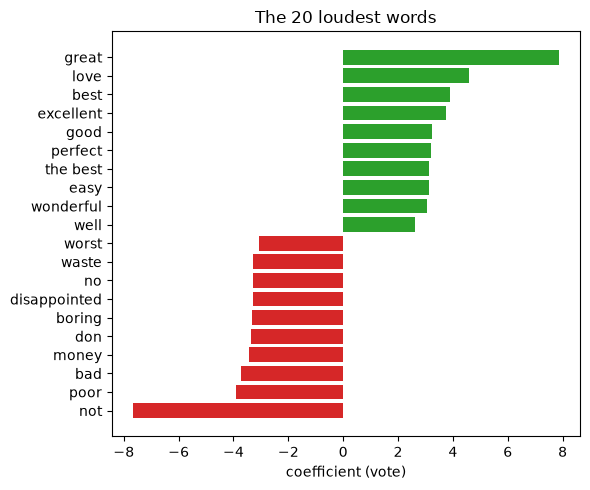

In [8]:
top = pd.concat([coefs.nsmallest(10), coefs.nlargest(10)]).sort_values()
plt.figure(figsize=(6, 5))
plt.barh(top.index, top.values, color=["tab:red" if v < 0 else "tab:green" for v in top.values])
plt.xlabel("coefficient (vote)"); plt.title("The 20 loudest words")
plt.tight_layout(); plt.show()

## 5. Where it fails

In [9]:
tricky = ["This is not good.",
          "Not bad at all, I'm pleasantly surprised.",
          "Oh great, another charger that died after a week. Just what I needed.",
          "I was expecting to hate it but it is wonderful.",
          "Works."]

for review, p in zip(tricky, model.predict_proba(tricky)[:, 1]):
    print(f"P(positive) = {p:.3f}   {review}")

P(positive) = 0.153   This is not good.
P(positive) = 0.178   Not bad at all, I'm pleasantly surprised.
P(positive) = 0.533   Oh great, another charger that died after a week. Just what I needed.
P(positive) = 0.640   I was expecting to hate it but it is wonderful.
P(positive) = 0.918   Works.


*Not bad at all* still scores negative: the bigram *not bad* has a small positive vote, but *not* and *bad* each carry large negative votes and they win. Sarcasm lands near 0.5.

### The most confident mistakes

In [10]:
scored = test.assign(p_positive=model.predict_proba(test["text"])[:, 1])
wrong = scored[(scored["p_positive"] > 0.5) != (scored["label"] == 1)]
print(f"{len(wrong)} of {len(test):,} test reviews misclassified\n")
pd.set_option("display.max_colwidth", 220)
wrong.sort_values("p_positive")[["label", "p_positive", "text"]].head(3)

232 of 2,000 test reviews misclassified



,label,p_positive,text
8974,1,0.146026,Plastic seat - biscuit color. Replaced our cheaper seats with the quality of a Kohler. Not a bad price. Prefer plastic because the finish does not degrade from bleach tablets.
8572,1,0.153778,"deviated too much from the book, but still enjoyable. i love the book, and find the series ok... not great though. there are a couple of deviations which were quite annoying and too much...1. why must Remigius be gay..."
8485,1,0.185641,Had No Problems... My husband and I got this mobile to match the Hampton bedding set and I have not experienced any of the problems mentioned by other reviewers.One thing to make note of however is that the assembly ...


In [11]:
wrong.sort_values("p_positive")[["label", "p_positive", "text"]].tail(3)

,label,p_positive,text
5353,0,0.834304,"Experiment in Terror by Schifrin is a Bore! I keep on saying the best Lalo Schifrin is on his Jazz and soundtrack albums. He is specially a master in scenes of action on which he lays music with fresh movement, full ..."
3708,0,0.892992,Great easy to use. Havent used yet but plan on soon it looks easy to use and I will soon but just havent yet
6582,0,0.900126,"Thai Fresh Lemongrass - 8 stalks. Exactly what I wanted, will reorder when I run out. Came fresh and makes the best tea. Thank you very much.."


The first table holds positive reviews the model called negative: mixed reviews with *not*, *problems*, *not great though*. The second holds reviews **labelled** negative that the model called positive, and at least two of them (*"Great easy to use…"*, *"Exactly what I wanted, will reorder…"*) read as positive to any human. The labels are wrong, not the model. Real labels are noisy, and no model can score 100% against noisy labels.

## Quiz answers

1. How strongly that word (or word pair) pushes a review towards *positive* (if positive) or *negative* (if negative), for a given TF-IDF value.
2. The stop-word list includes *not* and *no*, which are among the strongest sentiment signals.
3. The bigram *not bad* has its own small positive vote, but *not* (−7.66) and *bad* (−3.72) are still counted separately and outvote it.
4. **Recall** of the negative class. Lower the threshold for "unhappy" (for example, flag any review with P(positive) below 0.7 instead of 0.5): more complaints caught, more false alarms (03.7).
5. Any two of: noisy labels, negation and sarcasm the features cannot represent, mixed reviews, words never seen in training.

**Next:** [09.3 Embeddings](../03-embeddings/)